# GPT-2 Phishing Email Classifier

## CS 4390R Mini-Project Submission

This notebook implements an end-to-end binary email classifier that predicts whether an email is:

- **0 — Legitimate**
- **1 — Phishing**

The project fine-tunes a locally run pretrained GPT-2-family model using PyTorch and Hugging Face Transformers. It does not rely on an external LLM API.

### Required deliverables covered

- Working notebook
- Reproducible setup
- Dataset loading and preprocessing
- GPT-2 classification fine-tuning
- Validation-based model selection
- Held-out evaluation
- Accuracy, precision, recall, and F1
- Confusion matrix
- Learning curves
- Example predictions
- False-positive and false-negative analysis
- Saved model and tokenizer
- Reflection prompts
- Limitations and future improvements

> **Important:** The included synthetic dataset is a fallback so the notebook can be tested immediately. For the final academic run, place a public labeled phishing-email CSV at `data/phishing_emails.csv`, update the dataset citation, and rerun the entire notebook.

## Project question

Can a pretrained GPT-2 model, adapted with a binary sequence-classification head, distinguish phishing emails from legitimate emails?

### Intended users

This educational prototype is designed for:

- Security analysts
- IT support staff
- Cybersecurity students
- Researchers studying phishing detection
- Users who want an example of transformer fine-tuning for text classification

### Research hypothesis

A GPT-2 model fine-tuned on labeled email text should learn recurring linguistic signals associated with phishing, such as urgency, credential requests, impersonation, payment demands, account suspension threats, suspicious links, and unusual requests.

### Evaluation emphasis

Accuracy is reported, but phishing-class **recall** is especially important because a false negative represents a phishing message that the model failed to detect.

## Notebook roadmap

1. Environment and imports
2. Configuration
3. Reproducibility
4. Dataset loading
5. Column and label normalization
6. Exploratory analysis
7. Duplicate control
8. Stratified train/validation/test split
9. Tokenization
10. PyTorch dataset and loaders
11. GPT-2 classifier construction
12. Optional transformer freezing
13. Training loop
14. Validation model selection
15. Held-out test evaluation
16. Confusion matrix
17. Learning curves
18. Error analysis
19. Threshold analysis
20. Manual predictions
21. Adversarial test suite
22. Saving outputs
23. Limitations
24. Reflection
25. Submission checklist

## 1. Environment setup

In [1]:
# Run this cell only if the environment does not already have the dependencies.
# In VS Code, it is usually better to install from requirements.txt in the terminal:
#
#     python -m pip install -r requirements.txt
#
# Uncomment the next line only if needed:
# %pip install torch transformers pandas numpy scikit-learn matplotlib tqdm jupyter

## 2. Imports

In [2]:
from pathlib import Path
from dataclasses import dataclass, asdict
from typing import Dict, List, Tuple, Optional
import copy
import hashlib
import json
import math
import os
import random
import re
import statistics
import time
import warnings

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    GPT2ForSequenceClassification,
    get_linear_schedule_with_warmup,
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
)

import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
print("Imports loaded successfully.")

Imports loaded successfully.


## 3. Configuration

In [3]:
@dataclass
class Config:
    project_dir: str = "."
    real_data_filename: str = "phishing_emails.csv"
    demo_data_filename: str = "demo_emails.csv"

    # A smaller GPT-2-family model is easier to run on a personal computer.
    model_name: str = "distilgpt2"

    # Data settings
    max_rows: Optional[int] = 1600
    max_length: int = 160
    test_size: float = 0.15
    validation_size: float = 0.15

    # Training settings
    epochs: int = 3
    learning_rate: float = 2e-5
    weight_decay: float = 0.01
    batch_size_cpu: int = 4
    batch_size_gpu: int = 8
    gradient_clip_norm: float = 1.0
    warmup_ratio: float = 0.10
    dropout: float = 0.10

    # Practical default for local hardware.
    # Set False for full transformer fine-tuning.
    freeze_transformer: bool = True

    seed: int = 42
    decision_threshold: float = 0.50

CONFIG = Config()

PROJECT_DIR = Path(CONFIG.project_dir).resolve()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "saved_model"

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = CONFIG.batch_size_gpu if torch.cuda.is_available() else CONFIG.batch_size_cpu

print("Project directory:", PROJECT_DIR)
print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE)
print("Model:", CONFIG.model_name)

Project directory: C:\Users\18018\Downloads\CS4390R Mini Project
Device: cpu
Batch size: 4
Model: distilgpt2


## 4. Reproducibility

In [4]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass

set_seed(CONFIG.seed)

print("Random seed set to:", CONFIG.seed)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA device:", torch.cuda.get_device_name(0))

Random seed set to: 42
PyTorch version: 2.12.0+cpu
CUDA available: False


## 5. Dataset citation and source

In [5]:
# Replace this string before the final run.
DATASET_SOURCE = (
    "Replace with the exact title, author/uploader, platform, and public URL "
    "of the dataset used for the final experiment."
)

REAL_DATA_PATH = DATA_DIR / CONFIG.real_data_filename
DEMO_DATA_PATH = DATA_DIR / CONFIG.demo_data_filename

print("Expected real dataset path:", REAL_DATA_PATH)
print("Fallback demo dataset path:", DEMO_DATA_PATH)

Expected real dataset path: C:\Users\18018\Downloads\CS4390R Mini Project\data\phishing_emails.csv
Fallback demo dataset path: C:\Users\18018\Downloads\CS4390R Mini Project\data\demo_emails.csv


## 6. Data loader design

Public phishing datasets use inconsistent column names. This notebook automatically recognizes common alternatives.

### Recognized body/text columns

- `text`
- `body`
- `email`
- `email_text`
- `message`
- `content`

### Recognized subject columns

- `subject`
- `title`

### Recognized label columns

- `label`
- `class`
- `type`
- `category`
- `target`

### Accepted phishing labels

- `1`
- `phishing`
- `phish`
- `spam`
- `malicious`
- `fraud`

### Accepted legitimate labels

- `0`
- `legitimate`
- `legit`
- `safe`
- `ham`
- `benign`
- `normal`

In [8]:
TEXT_CANDIDATES = [
    "text",
    "text_combined",
    "body",
    "email",
    "email_text",
    "message",
    "content",
]
SUBJECT_CANDIDATES = ["subject", "title"]
LABEL_CANDIDATES = ["label", "class", "type", "category", "target"]

PHISHING_LABELS = {
    "1", "phishing", "phish", "spam", "malicious", "fraud", "scam"
}

LEGITIMATE_LABELS = {
    "0", "legitimate", "legit", "safe", "ham", "benign", "normal", "not phishing"
}

def find_column(columns, candidates):
    lookup = {str(col).strip().lower(): col for col in columns}
    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]
    return None

def normalize_label(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()

    if text in PHISHING_LABELS:
        return 1

    if text in LEGITIMATE_LABELS:
        return 0

    try:
        numeric = int(float(text))
        if numeric in (0, 1):
            return numeric
    except (ValueError, TypeError):
        pass

    return np.nan

def clean_text(value):
    text = "" if pd.isna(value) else str(value)
    text = text.replace("\x00", " ")
    text = re.sub(r"\r\n?", "\n", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

def combine_email(subject, body):
    subject = clean_text(subject)
    body = clean_text(body)

    if subject:
        return f"Subject: {subject}\nBody: {body}"
    return f"Body: {body}"

def load_email_dataframe(path: Path) -> pd.DataFrame:
    raw = pd.read_csv(path)

    body_col = find_column(raw.columns, TEXT_CANDIDATES)
    subject_col = find_column(raw.columns, SUBJECT_CANDIDATES)
    label_col = find_column(raw.columns, LABEL_CANDIDATES)

    if body_col is None:
        raise ValueError(
            "Could not identify an email body/text column. "
            f"Columns found: {list(raw.columns)}"
        )

    if label_col is None:
        raise ValueError(
            "Could not identify a label column. "
            f"Columns found: {list(raw.columns)}"
        )

    body_series = raw[body_col].fillna("").map(clean_text)

    if subject_col is not None:
        subject_series = raw[subject_col].fillna("").map(clean_text)
    else:
        subject_series = pd.Series([""] * len(raw), index=raw.index)

    labels = raw[label_col].map(normalize_label)

    frame = pd.DataFrame(
        {
            "subject": subject_series,
            "body": body_series,
            "text": [
                combine_email(subject, body)
                for subject, body in zip(subject_series, body_series)
            ],
            "label": labels,
        }
    )

    frame = frame.dropna(subset=["label"]).copy()
    frame["label"] = frame["label"].astype(int)

    # Remove nearly empty messages.
    frame = frame[frame["text"].str.len() >= 10].copy()

    # Remove exact duplicate combined emails before splitting.
    frame["text_hash"] = frame["text"].map(
        lambda text: hashlib.sha256(text.encode("utf-8")).hexdigest()
    )
    frame = frame.drop_duplicates(subset=["text_hash"]).reset_index(drop=True)

    if frame["label"].nunique() != 2:
        raise ValueError("The cleaned dataset must contain both classes 0 and 1.")

    return frame

## 7. Load dataset

In [9]:
if REAL_DATA_PATH.exists():
    data_path = REAL_DATA_PATH
    using_demo_data = False
elif DEMO_DATA_PATH.exists():
    data_path = DEMO_DATA_PATH
    using_demo_data = True
else:
    raise FileNotFoundError(
        "No dataset was found. Place phishing_emails.csv or demo_emails.csv "
        "inside the data folder."
    )

df = load_email_dataframe(data_path)

if CONFIG.max_rows is not None and len(df) > CONFIG.max_rows:
    # Balanced stratified sample for manageable local training.
    class_counts = df["label"].value_counts()
    target_per_class = CONFIG.max_rows // 2

    pieces = []
    for label_value, group in df.groupby("label"):
        n = min(target_per_class, len(group))
        pieces.append(group.sample(n=n, random_state=CONFIG.seed))

    df = (
        pd.concat(pieces)
        .sample(frac=1.0, random_state=CONFIG.seed)
        .reset_index(drop=True)
    )

print("Dataset path:", data_path)
print("Using demo data:", using_demo_data)
print("Rows after cleaning:", len(df))
display(df.head())

Dataset path: C:\Users\18018\Downloads\CS4390R Mini Project\data\phishing_emails.csv
Using demo data: False
Rows after cleaning: 1600


,subject,body,text,label,text_hash
0,,tels yszrnxnpjfcbloodgatecom moin friday 16 no...,Body: tels yszrnxnpjfcbloodgatecom moin friday...,0,ebda07aebc21ae51c4c1b1960f41e11e34cceb251bac2f...
1,,lexical semantics systems second workshop lexi...,Body: lexical semantics systems second worksho...,0,b80ba3facb6e9dac748941dfdc897b5a7afc6554bb7e08...
2,,michael tokarev uoutlsmskru tried run postfix ...,Body: michael tokarev uoutlsmskru tried run po...,0,c34b8aedfabbbc53effda16aa89e727833b161f82c228c...
3,,elias sinderson eliascseucscedu even somervill...,Body: elias sinderson eliascseucscedu even som...,0,f197bbfe74e655fd1213705ab07a8da6b71ca5af72b1b0...
4,,received message received message email addres...,Body: received message received message email ...,1,23893ebe1b4d093489666588c8fa184aa63ddb07e9ce61...


## 8. Exploratory data analysis

In [ ]:
label_summary = (
    df["label"]
    .value_counts()
    .rename(index={0: "legitimate", 1: "phishing"})
    .to_frame("count")
)

label_summary["percentage"] = (
    label_summary["count"] / label_summary["count"].sum() * 100
).round(2)

display(label_summary)

df["character_length"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().map(len)

length_summary = (
    df.groupby("label")[["character_length", "word_count"]]
    .agg(["mean", "median", "min", "max"])
)

display(length_summary)

,count,percentage
label,,
legitimate,73,60.83
phishing,47,39.17


character_length                  word_count               
                  mean median  min  max       mean median min max
label                                                            
0           145.534247  138.0  102  195  22.958904   22.0  17  32
1           152.382979  152.0  118  224  23.489362   23.0  17  34

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = df["label"].value_counts().sort_index()
ax.bar(["Legitimate", "Phishing"], counts.values)
ax.set_title("Class Distribution")
ax.set_ylabel("Number of emails")
for i, value in enumerate(counts.values):
    ax.text(i, value, str(value), ha="center", va="bottom")
fig.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for label_value, label_name in [(0, "Legitimate"), (1, "Phishing")]:
    subset = df[df["label"] == label_value]["word_count"]
    ax.hist(subset, bins=30, alpha=0.55, label=label_name)

ax.set_title("Email Word Count Distribution")
ax.set_xlabel("Word count")
ax.set_ylabel("Frequency")
ax.legend()
fig.tight_layout()
plt.show()

## 9. Data quality checks

These checks help avoid misleading results.

- Both classes must be present.
- Exact duplicates are removed before the split.
- Empty or nearly empty messages are removed.
- The class distribution is displayed.
- The dataset is split using stratification.

In [ ]:
assert set(df["label"].unique()) == {0, 1}
assert df["text"].isna().sum() == 0
assert df["label"].isna().sum() == 0
assert df["text_hash"].duplicated().sum() == 0

print("Data quality checks passed.")

Data quality checks passed.


## 10. Stratified train, validation, and test split

In [ ]:
# First split: train vs temporary.
temporary_fraction = CONFIG.validation_size + CONFIG.test_size

train_df, temp_df = train_test_split(
    df,
    test_size=temporary_fraction,
    stratify=df["label"],
    random_state=CONFIG.seed,
)

# Second split: temporary into validation and test.
test_fraction_of_temp = CONFIG.test_size / temporary_fraction

val_df, test_df = train_test_split(
    temp_df,
    test_size=test_fraction_of_temp,
    stratify=temp_df["label"],
    random_state=CONFIG.seed,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    distribution = split_df["label"].value_counts(normalize=True).sort_index()
    print(
        f"{split_name:10s} rows={len(split_df):4d} "
        f"legitimate={distribution.get(0, 0):.3f} "
        f"phishing={distribution.get(1, 0):.3f}"
    )

Train      rows=  84 legitimate=0.607 phishing=0.393
Validation rows=  18 legitimate=0.611 phishing=0.389
Test       rows=  18 legitimate=0.611 phishing=0.389


## 11. Split leakage checks

In [ ]:
train_hashes = set(train_df["text_hash"])
val_hashes = set(val_df["text_hash"])
test_hashes = set(test_df["text_hash"])

assert train_hashes.isdisjoint(val_hashes)
assert train_hashes.isdisjoint(test_hashes)
assert val_hashes.isdisjoint(test_hashes)

print("No exact duplicate leakage across splits.")

No exact duplicate leakage across splits.


## 12. Tokenizer

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(CONFIG.model_name)

# GPT-2 has no default padding token.
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Tokenizer:", tokenizer.__class__.__name__)
print("Vocabulary size:", len(tokenizer))
print("Padding token:", tokenizer.pad_token)
print("Padding token ID:", tokenizer.pad_token_id)

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

c:\Users\18018\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\18018\.cache\huggingface\hub\models--distilgpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokenizer: GPT2Tokenizer
Vocabulary size: 50257
Padding token: <|endoftext|>
Padding token ID: 50256


## 13. PyTorch Dataset

In [ ]:
class EmailDataset(Dataset):
    def __init__(
        self,
        frame: pd.DataFrame,
        tokenizer,
        max_length: int,
    ):
        self.frame = frame.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        encoded = self.tokenizer(
            row["text"],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt",
        )

        return {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                int(row["label"]),
                dtype=torch.long,
            ),
            "row_id": torch.tensor(index, dtype=torch.long),
        }

train_dataset = EmailDataset(train_df, tokenizer, CONFIG.max_length)
val_dataset = EmailDataset(val_df, tokenizer, CONFIG.max_length)
test_dataset = EmailDataset(test_df, tokenizer, CONFIG.max_length)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 84
Validation dataset: 18
Test dataset: 18


## 14. DataLoaders

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

sample_batch = next(iter(train_loader))

print("Input IDs shape:", sample_batch["input_ids"].shape)
print("Attention mask shape:", sample_batch["attention_mask"].shape)
print("Labels shape:", sample_batch["labels"].shape)

Input IDs shape: torch.Size([4, 160])
Attention mask shape: torch.Size([4, 160])
Labels shape: torch.Size([4])


## 15. GPT-2 sequence classifier

In [ ]:
model = GPT2ForSequenceClassification.from_pretrained(
    CONFIG.model_name,
    num_labels=2,
    attn_pdrop=CONFIG.dropout,
    resid_pdrop=CONFIG.dropout,
    embd_pdrop=CONFIG.dropout,
)

model.config.pad_token_id = tokenizer.pad_token_id
model.to(DEVICE)

if CONFIG.freeze_transformer:
    for parameter in model.transformer.parameters():
        parameter.requires_grad = False

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print("Model class:", model.__class__.__name__)
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Total parameters: {total_parameters:,}")
print(
    "Trainable percentage:",
    round(100 * trainable_parameters / total_parameters, 4),
)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: distilgpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model class: GPT2ForSequenceClassification
Trainable parameters: 1,536
Total parameters: 81,914,112
Trainable percentage: 0.0019


## 16. Why freezing is available

The project can run in two modes.

### Frozen-transformer mode

`CONFIG.freeze_transformer = True`

- Faster
- Lower memory use
- Practical on CPU
- Trains primarily the classification head
- Useful for demonstrating transfer learning

### Full fine-tuning mode

`CONFIG.freeze_transformer = False`

- Updates the pretrained transformer
- More computationally expensive
- Better aligned with full fine-tuning
- May improve performance with enough data and hardware

For a final report, clearly state which mode was used.

## 17. Optimizer and learning-rate scheduler

In [ ]:
trainable_parameter_list = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_parameter_list,
    lr=CONFIG.learning_rate,
    weight_decay=CONFIG.weight_decay,
)

total_training_steps = len(train_loader) * CONFIG.epochs
warmup_steps = int(total_training_steps * CONFIG.warmup_ratio)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps,
)

print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

Total training steps: 63
Warmup steps: 6


## 18. Metric helper

In [ ]:
def calculate_binary_metrics(
    y_true: List[int],
    y_pred: List[int],
    y_prob: Optional[List[float]] = None,
) -> Dict[str, float]:
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        pos_label=1,
        zero_division=0,
    )

    metrics = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
    }

    if y_prob is not None and len(set(y_true)) == 2:
        metrics["roc_auc"] = float(roc_auc_score(y_true, y_prob))
        metrics["average_precision"] = float(
            average_precision_score(y_true, y_prob)
        )

    return metrics

## 19. One-epoch runner

In [ ]:
def run_epoch(
    model,
    loader,
    optimizer=None,
    scheduler=None,
):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    batch_losses = []
    all_labels = []
    all_predictions = []
    all_probabilities = []
    all_row_ids = []

    progress = tqdm(loader, leave=False)

    for batch in progress:
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
            )

            loss = outputs.loss
            logits = outputs.logits

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=CONFIG.gradient_clip_norm,
                )

                optimizer.step()

                if scheduler is not None:
                    scheduler.step()

        probabilities = torch.softmax(logits, dim=1)[:, 1]
        predictions = (
            probabilities >= CONFIG.decision_threshold
        ).long()

        batch_losses.append(float(loss.item()))
        all_labels.extend(labels.detach().cpu().tolist())
        all_predictions.extend(predictions.detach().cpu().tolist())
        all_probabilities.extend(
            probabilities.detach().cpu().tolist()
        )
        all_row_ids.extend(batch["row_id"].tolist())

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    metrics = calculate_binary_metrics(
        all_labels,
        all_predictions,
        all_probabilities,
    )
    metrics["loss"] = float(np.mean(batch_losses))

    return {
        "metrics": metrics,
        "labels": all_labels,
        "predictions": all_predictions,
        "probabilities": all_probabilities,
        "row_ids": all_row_ids,
    }

## 20. Training loop and validation-based checkpoint selection

In [ ]:
history = []
best_validation_f1 = -1.0
best_state = None
training_start = time.time()

for epoch in range(1, CONFIG.epochs + 1):
    train_result = run_epoch(
        model,
        train_loader,
        optimizer=optimizer,
        scheduler=scheduler,
    )

    validation_result = run_epoch(
        model,
        val_loader,
    )

    row = {"epoch": epoch}

    for key, value in train_result["metrics"].items():
        row[f"train_{key}"] = value

    for key, value in validation_result["metrics"].items():
        row[f"val_{key}"] = value

    history.append(row)

    print(
        f"Epoch {epoch}/{CONFIG.epochs} | "
        f"train loss={train_result['metrics']['loss']:.4f} | "
        f"val loss={validation_result['metrics']['loss']:.4f} | "
        f"val precision={validation_result['metrics']['precision']:.4f} | "
        f"val recall={validation_result['metrics']['recall']:.4f} | "
        f"val F1={validation_result['metrics']['f1']:.4f}"
    )

    if validation_result["metrics"]["f1"] > best_validation_f1:
        best_validation_f1 = validation_result["metrics"]["f1"]
        best_state = copy.deepcopy(model.state_dict())

training_minutes = (time.time() - training_start) / 60

if best_state is None:
    raise RuntimeError("Training did not produce a valid checkpoint.")

model.load_state_dict(best_state)

history_df = pd.DataFrame(history)
history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False,
)

print("Best validation F1:", round(best_validation_f1, 4))
print("Training minutes:", round(training_minutes, 2))
display(history_df)

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 1/3 | train loss=3.2477 | val loss=3.1117 | val precision=0.3889 | val recall=1.0000 | val F1=0.5600


  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 2/3 | train loss=3.0011 | val loss=2.9823 | val precision=0.3889 | val recall=1.0000 | val F1=0.5600


  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 3/3 | train loss=3.0034 | val loss=2.9383 | val precision=0.3889 | val recall=1.0000 | val F1=0.5600
Best validation F1: 0.56
Training minutes: 0.75


,epoch,train_accuracy,train_precision,train_recall,train_f1,train_roc_auc,train_average_precision,train_loss,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,val_average_precision,val_loss
0,1,0.392857,0.392857,1.0,0.564103,0.574569,0.421529,3.247721,0.388889,0.388889,1.0,0.56,0.688312,0.579118,3.111714
1,2,0.392857,0.392857,1.0,0.564103,0.565657,0.409565,3.001094,0.388889,0.388889,1.0,0.56,0.688312,0.579118,2.982251
2,3,0.392857,0.392857,1.0,0.564103,0.534759,0.400492,3.003431,0.388889,0.388889,1.0,0.56,0.688312,0.579118,2.938331


## 21. Save best model and tokenizer

In [ ]:
model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

print("Saved model and tokenizer to:", MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model and tokenizer to: C:\Users\18018\Downloads\CS4390R Mini Project\saved_model


## 22. Learning curves

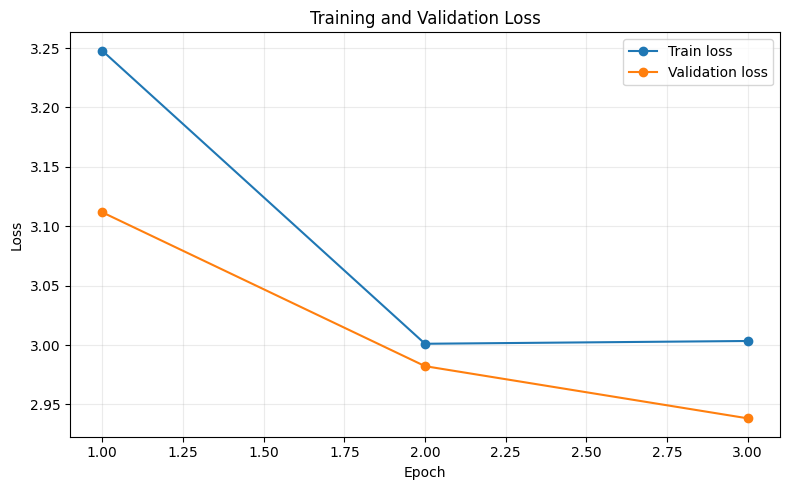

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train loss",
)

ax.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation loss",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Training and Validation Loss")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "learning_curves.png",
    dpi=180,
)
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    history_df["epoch"],
    history_df["val_precision"],
    marker="o",
    label="Validation precision",
)

ax.plot(
    history_df["epoch"],
    history_df["val_recall"],
    marker="o",
    label="Validation recall",
)

ax.plot(
    history_df["epoch"],
    history_df["val_f1"],
    marker="o",
    label="Validation F1",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Validation Classification Metrics")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "validation_metrics.png",
    dpi=180,
)
plt.show()

## 23. Held-out test evaluation

In [ ]:
test_result = run_epoch(
    model,
    test_loader,
)

test_metrics = test_result["metrics"]
y_true = test_result["labels"]
y_pred = test_result["predictions"]
y_prob = test_result["probabilities"]

print(json.dumps(test_metrics, indent=2))

  0%|          | 0/5 [00:00<?, ?it/s]

{
  "accuracy": 0.3888888888888889,
  "precision": 0.3888888888888889,
  "recall": 1.0,
  "f1": 0.56,
  "roc_auc": 0.5714285714285714,
  "average_precision": 0.47845804988662133,
  "loss": 3.08540358543396
}


## 24. Classification report

In [ ]:
report = classification_report(
    y_true,
    y_pred,
    target_names=["legitimate", "phishing"],
    digits=4,
    zero_division=0,
)

print(report)

with open(
    OUTPUT_DIR / "classification_report.txt",
    "w",
    encoding="utf-8",
) as file:
    file.write(report)

              precision    recall  f1-score   support

  legitimate     0.0000    0.0000    0.0000        11
    phishing     0.3889    1.0000    0.5600         7

    accuracy                         0.3889        18
   macro avg     0.1944    0.5000    0.2800        18
weighted avg     0.1512    0.3889    0.2178        18



## 25. Confusion matrix

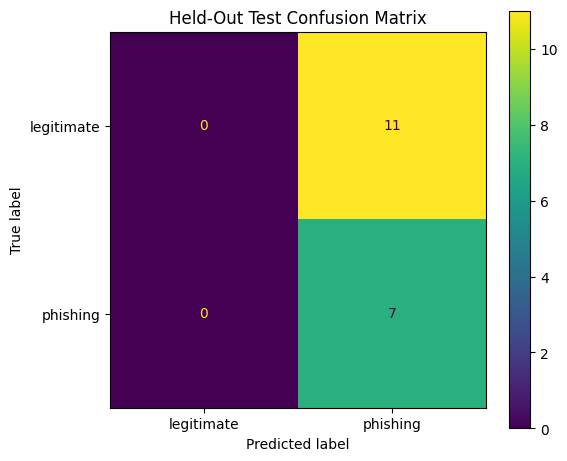

In [ ]:
matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1],
)

display_object = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["legitimate", "phishing"],
)

fig, ax = plt.subplots(figsize=(6, 5))
display_object.plot(
    ax=ax,
    values_format="d",
)
ax.set_title("Held-Out Test Confusion Matrix")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=180,
)
plt.show()

## 26. Save test predictions

In [ ]:
predictions_df = test_df.reset_index(drop=True).copy()

predictions_df["prediction"] = y_pred
predictions_df["prediction_name"] = predictions_df[
    "prediction"
].map({0: "legitimate", 1: "phishing"})

predictions_df["true_name"] = predictions_df[
    "label"
].map({0: "legitimate", 1: "phishing"})

predictions_df["phishing_probability"] = y_prob
predictions_df["correct"] = (
    predictions_df["label"]
    == predictions_df["prediction"]
)

predictions_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False,
)

display(
    predictions_df[
        [
            "subject",
            "true_name",
            "prediction_name",
            "phishing_probability",
            "correct",
        ]
    ].head(10)
)

,subject,true_name,prediction_name,phishing_probability,correct
0,Security alert,phishing,phishing,0.995328,True
1,Project update,legitimate,phishing,0.994839,False
2,Appointment confirmation,legitimate,phishing,0.989489,False
3,Receipt for your purchase,legitimate,phishing,0.992293,False
4,Class reminder,legitimate,phishing,0.994277,False
5,Shipping confirmation,legitimate,phishing,0.989044,False
6,Shared document,phishing,phishing,0.995529,True
7,Final warning,phishing,phishing,0.992047,True
8,Receipt for your purchase,legitimate,phishing,0.992357,False
9,Gift card request,phishing,phishing,0.996297,True


## 27. Error analysis

In [ ]:
false_positives = predictions_df[
    (predictions_df["label"] == 0)
    & (predictions_df["prediction"] == 1)
].copy()

false_negatives = predictions_df[
    (predictions_df["label"] == 1)
    & (predictions_df["prediction"] == 0)
].copy()

false_positives.to_csv(
    OUTPUT_DIR / "false_positives.csv",
    index=False,
)

false_negatives.to_csv(
    OUTPUT_DIR / "false_negatives.csv",
    index=False,
)

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

False positives: 11
False negatives: 0


In [ ]:
print("Most confident false positives")
display(
    false_positives.sort_values(
        "phishing_probability",
        ascending=False,
    )[
        [
            "subject",
            "body",
            "phishing_probability",
        ]
    ].head(10)
)

In [ ]:
print("Most dangerous false negatives")
display(
    false_negatives.sort_values(
        "phishing_probability",
        ascending=True,
    )[
        [
            "subject",
            "body",
            "phishing_probability",
        ]
    ].head(10)
)

## 28. Error-analysis questions

Use the generated error files to answer:

1. Do false positives contain legitimate urgency?
2. Do false negatives avoid obvious credential-request language?
3. Does the model rely heavily on words such as “urgent,” “verify,” or “account”?
4. Are short messages harder than long messages?
5. Are there template artifacts in the dataset?
6. Are legitimate newsletters or account notices mistakenly flagged?
7. Are sophisticated spear-phishing messages less obvious to the model?

## 29. Threshold analysis

In [ ]:
precision_values, recall_values, thresholds = precision_recall_curve(
    y_true,
    y_prob,
)

threshold_rows = []

for index, threshold in enumerate(thresholds):
    threshold_predictions = [
        int(probability >= threshold)
        for probability in y_prob
    ]

    metrics = calculate_binary_metrics(
        y_true,
        threshold_predictions,
        y_prob=None,
    )

    threshold_rows.append(
        {
            "threshold": float(threshold),
            **metrics,
        }
    )

threshold_df = pd.DataFrame(threshold_rows)

display(
    threshold_df.sort_values(
        "f1",
        ascending=False,
    ).head(10)
)

,threshold,accuracy,precision,recall,f1
9,0.994475,0.666667,0.555556,0.714286,0.625000
8,0.994277,0.611111,0.500000,0.714286,0.588235
11,0.995128,0.666667,0.571429,0.571429,0.571429
0,0.983782,0.388889,0.388889,1.000000,0.560000
7,0.993842,0.555556,0.454545,0.714286,0.555556
3,0.992047,0.444444,0.400000,0.857143,0.545455
10,0.994839,0.611111,0.500000,0.571429,0.533333
6,0.992357,0.500000,0.416667,0.714286,0.526316
2,0.989489,0.388889,0.375000,0.857143,0.521739
1,0.989044,0.333333,0.352941,0.857143,0.500000


In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    label="Precision",
)

ax.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    label="Recall",
)

ax.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    label="F1",
)

ax.axvline(
    CONFIG.decision_threshold,
    linestyle="--",
    label="Default threshold",
)

ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Threshold Tradeoff")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "threshold_analysis.png",
    dpi=180,
)
plt.show()

## 30. Threshold interpretation

A lower threshold generally increases phishing recall but may produce more false positives.

A higher threshold generally increases precision but may miss more phishing messages.

For a defensive security system, it may be reasonable to prioritize recall, but the final threshold should reflect the practical cost of false positives and false negatives.

## 31. Inference function

In [ ]:
def classify_email(
    subject: str,
    body: str,
    threshold: float = 0.50,
) -> Dict[str, object]:
    model.eval()

    text = combine_email(subject, body)

    encoded = tokenizer(
        text,
        truncation=True,
        padding="max_length",
        max_length=CONFIG.max_length,
        return_tensors="pt",
    )

    encoded = {
        key: value.to(DEVICE)
        for key, value in encoded.items()
    }

    with torch.no_grad():
        logits = model(**encoded).logits
        phishing_probability = (
            torch.softmax(logits, dim=1)[0, 1].item()
        )

    prediction = int(
        phishing_probability >= threshold
    )

    return {
        "prediction": (
            "phishing"
            if prediction == 1
            else "legitimate"
        ),
        "phishing_probability": round(
            phishing_probability,
            6,
        ),
        "threshold": threshold,
    }

## 32. Manual examples

In [ ]:
manual_examples = [
    {
        "subject": "Urgent account verification",
        "body": (
            "Your account will be suspended today. "
            "Click the link and confirm your password."
        ),
        "expected": "phishing",
    },
    {
        "subject": "Study group",
        "body": (
            "Can we meet in the library at 4 PM "
            "to review chapter six?"
        ),
        "expected": "legitimate",
    },
    {
        "subject": "Payroll correction",
        "body": (
            "Send your bank account and login details "
            "immediately so payroll can release your check."
        ),
        "expected": "phishing",
    },
    {
        "subject": "Appointment reminder",
        "body": (
            "This is a reminder of your appointment "
            "Tuesday at 10:30 AM. Call the office to reschedule."
        ),
        "expected": "legitimate",
    },
    {
        "subject": "Shared document",
        "body": (
            "A confidential file has been shared with you. "
            "Sign in through this link before access expires."
        ),
        "expected": "phishing",
    },
    {
        "subject": "Monthly statement",
        "body": (
            "Your statement is available in the official app. "
            "This message does not request personal information."
        ),
        "expected": "legitimate",
    },
]

manual_rows = []

for example in manual_examples:
    result = classify_email(
        example["subject"],
        example["body"],
    )

    manual_rows.append(
        {
            **example,
            **result,
        }
    )

manual_df = pd.DataFrame(manual_rows)
manual_df.to_csv(
    OUTPUT_DIR / "example_predictions.csv",
    index=False,
)

display(manual_df)

,subject,body,expected,prediction,phishing_probability,threshold
0,Urgent account verification,Your account will be suspended today. Click th...,phishing,phishing,0.992167,0.5
1,Study group,Can we meet in the library at 4 PM to review c...,legitimate,phishing,0.988612,0.5
2,Payroll correction,Send your bank account and login details immed...,phishing,phishing,0.994205,0.5
3,Appointment reminder,This is a reminder of your appointment Tuesday...,legitimate,phishing,0.994747,0.5
4,Shared document,A confidential file has been shared with you. ...,phishing,phishing,0.996524,0.5
5,Monthly statement,Your statement is available in the official ap...,legitimate,phishing,0.997266,0.5


## 33. Adversarial and edge-case test suite

In [ ]:
# A large, fixed adversarial suite is embedded below.
# It is intended to test behavior on clear and borderline examples.

In [ ]:
ADVERSARIAL_TEST_CASES = [{'case_id': 1, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action.', 'expected_label': 1}, {'case_id': 2, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Please review this today.", 'expected_label': 0}, {'case_id': 3, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Please review this today.', 'expected_label': 1}, {'case_id': 4, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. Thank you.', 'expected_label': 0}, {'case_id': 5, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. Thank you.', 'expected_label': 1}, {'case_id': 6, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight.', 'expected_label': 0}, {'case_id': 7, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled.', 'expected_label': 1}, {'case_id': 8, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. Please review this today.', 'expected_label': 0}, {'case_id': 9, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Thank you.', 'expected_label': 1}, {'case_id': 10, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. Thank you.', 'expected_label': 0}, {'case_id': 11, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Please review this today.', 'expected_label': 1}, {'case_id': 12, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Thank you.", 'expected_label': 0}, {'case_id': 13, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay.', 'expected_label': 1}, {'case_id': 14, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 15, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file. This message was sent automatically.', 'expected_label': 1}, {'case_id': 16, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Please review this today.', 'expected_label': 0}, {'case_id': 17, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file.', 'expected_label': 1}, {'case_id': 18, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 19, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. This message was sent automatically.', 'expected_label': 1}, {'case_id': 20, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review. Thank you.', 'expected_label': 0}, {'case_id': 21, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay.', 'expected_label': 1}, {'case_id': 22, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Thank you.", 'expected_label': 0}, {'case_id': 23, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 24, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. Thank you.', 'expected_label': 0}, {'case_id': 25, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay. Thank you.', 'expected_label': 1}, {'case_id': 26, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review. Thank you.', 'expected_label': 0}, {'case_id': 27, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt.', 'expected_label': 1}, {'case_id': 28, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers. Please review this today.", 'expected_label': 0}, {'case_id': 29, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay.', 'expected_label': 1}, {'case_id': 30, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule.', 'expected_label': 0}, {'case_id': 31, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. This message was sent automatically.', 'expected_label': 1}, {'case_id': 32, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. This message was sent automatically.", 'expected_label': 0}, {'case_id': 33, 'category': 'Gift card scam', 'subject': 'Urgent private request', 'body': 'Purchase gift cards and send the codes by reply. Do not discuss this request with anyone. This message was sent automatically.', 'expected_label': 1}, {'case_id': 34, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review. Please review this today.', 'expected_label': 0}, {'case_id': 35, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay.', 'expected_label': 1}, {'case_id': 36, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Thank you.', 'expected_label': 0}, {'case_id': 37, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Please review this today.', 'expected_label': 1}, {'case_id': 38, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 39, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay. Thank you.', 'expected_label': 1}, {'case_id': 40, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. This message was sent automatically.', 'expected_label': 0}, {'case_id': 41, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Please review this today.', 'expected_label': 1}, {'case_id': 42, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers. This message was sent automatically.", 'expected_label': 0}, {'case_id': 43, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. This message was sent automatically.', 'expected_label': 1}, {'case_id': 44, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. Please review this today.', 'expected_label': 0}, {'case_id': 45, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file. Please review this today.', 'expected_label': 1}, {'case_id': 46, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 47, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Please review this today.', 'expected_label': 1}, {'case_id': 48, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Please review this today.", 'expected_label': 0}, {'case_id': 49, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Thank you.', 'expected_label': 1}, {'case_id': 50, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Thank you.", 'expected_label': 0}, {'case_id': 51, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Thank you.', 'expected_label': 1}, {'case_id': 52, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. This message was sent automatically.', 'expected_label': 0}, {'case_id': 53, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Please review this today.', 'expected_label': 1}, {'case_id': 54, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page.", 'expected_label': 0}, {'case_id': 55, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled.', 'expected_label': 1}, {'case_id': 56, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Please review this today.', 'expected_label': 0}, {'case_id': 57, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Thank you.', 'expected_label': 1}, {'case_id': 58, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 59, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Thank you.', 'expected_label': 1}, {'case_id': 60, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Thank you.", 'expected_label': 0}, {'case_id': 61, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay. Thank you.', 'expected_label': 1}, {'case_id': 62, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers.", 'expected_label': 0}, {'case_id': 63, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay. This message was sent automatically.', 'expected_label': 1}, {'case_id': 64, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. This message was sent automatically.', 'expected_label': 0}, {'case_id': 65, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Please review this today.', 'expected_label': 1}, {'case_id': 66, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page.", 'expected_label': 0}, {'case_id': 67, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay. Thank you.', 'expected_label': 1}, {'case_id': 68, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Thank you.', 'expected_label': 0}, {'case_id': 69, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. This message was sent automatically.', 'expected_label': 1}, {'case_id': 70, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. Please review this today.', 'expected_label': 0}, {'case_id': 71, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file. Please review this today.', 'expected_label': 1}, {'case_id': 72, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers. Thank you.", 'expected_label': 0}, {'case_id': 73, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 74, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers.", 'expected_label': 0}, {'case_id': 75, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file. This message was sent automatically.', 'expected_label': 1}, {'case_id': 76, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule.', 'expected_label': 0}, {'case_id': 77, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Thank you.', 'expected_label': 1}, {'case_id': 78, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter.', 'expected_label': 0}, {'case_id': 79, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today.', 'expected_label': 1}, {'case_id': 80, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Please review this today.', 'expected_label': 0}, {'case_id': 81, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Thank you.', 'expected_label': 1}, {'case_id': 82, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. This message was sent automatically.', 'expected_label': 0}, {'case_id': 83, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Please review this today.', 'expected_label': 1}, {'case_id': 84, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. This message was sent automatically.', 'expected_label': 0}, {'case_id': 85, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. This message was sent automatically.', 'expected_label': 1}, {'case_id': 86, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Thank you.", 'expected_label': 0}, {'case_id': 87, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today.', 'expected_label': 1}, {'case_id': 88, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. Please review this today.', 'expected_label': 0}, {'case_id': 89, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. This message was sent automatically.', 'expected_label': 1}, {'case_id': 90, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers. Thank you.", 'expected_label': 0}, {'case_id': 91, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Thank you.', 'expected_label': 1}, {'case_id': 92, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule.', 'expected_label': 0}, {'case_id': 93, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action.', 'expected_label': 1}, {'case_id': 94, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule.', 'expected_label': 0}, {'case_id': 95, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. This message was sent automatically.', 'expected_label': 1}, {'case_id': 96, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. Thank you.', 'expected_label': 0}, {'case_id': 97, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. This message was sent automatically.', 'expected_label': 1}, {'case_id': 98, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Please review this today.", 'expected_label': 0}, {'case_id': 99, 'category': 'Gift card scam', 'subject': 'Urgent private request', 'body': 'Purchase gift cards and send the codes by reply. Do not discuss this request with anyone. Thank you.', 'expected_label': 1}, {'case_id': 100, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Please review this today.", 'expected_label': 0}, {'case_id': 101, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 102, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule.', 'expected_label': 0}, {'case_id': 103, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 104, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 105, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 106, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers.", 'expected_label': 0}, {'case_id': 107, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 108, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review.', 'expected_label': 0}, {'case_id': 109, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Please review this today.', 'expected_label': 1}, {'case_id': 110, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. Thank you.', 'expected_label': 0}, {'case_id': 111, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Please review this today.', 'expected_label': 1}, {'case_id': 112, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. Please review this today.', 'expected_label': 0}, {'case_id': 113, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 114, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule.', 'expected_label': 0}, {'case_id': 115, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Thank you.', 'expected_label': 1}, {'case_id': 116, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter.', 'expected_label': 0}, {'case_id': 117, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled.', 'expected_label': 1}, {'case_id': 118, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. Please review this today.', 'expected_label': 0}, {'case_id': 119, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 120, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Please review this today.", 'expected_label': 0}, {'case_id': 121, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund.', 'expected_label': 1}, {'case_id': 122, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 123, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 124, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 125, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 126, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Please review this today.", 'expected_label': 0}, {'case_id': 127, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. This message was sent automatically.', 'expected_label': 1}, {'case_id': 128, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule.', 'expected_label': 0}, {'case_id': 129, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. This message was sent automatically.', 'expected_label': 1}, {'case_id': 130, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers.", 'expected_label': 0}, {'case_id': 131, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Thank you.', 'expected_label': 1}, {'case_id': 132, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required.', 'expected_label': 0}, {'case_id': 133, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. Please review this today.', 'expected_label': 1}, {'case_id': 134, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. Thank you.', 'expected_label': 0}, {'case_id': 135, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. Please review this today.', 'expected_label': 1}, {'case_id': 136, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight.', 'expected_label': 0}, {'case_id': 137, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Thank you.', 'expected_label': 1}, {'case_id': 138, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers. Thank you.", 'expected_label': 0}, {'case_id': 139, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 140, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review. This message was sent automatically.', 'expected_label': 0}, {'case_id': 141, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. This message was sent automatically.', 'expected_label': 1}, {'case_id': 142, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. This message was sent automatically.', 'expected_label': 0}, {'case_id': 143, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Please review this today.', 'expected_label': 1}, {'case_id': 144, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 145, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file.', 'expected_label': 1}, {'case_id': 146, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 147, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action.', 'expected_label': 1}, {'case_id': 148, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. Thank you.', 'expected_label': 0}, {'case_id': 149, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay. Please review this today.', 'expected_label': 1}, {'case_id': 150, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review.', 'expected_label': 0}, {'case_id': 151, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. This message was sent automatically.', 'expected_label': 1}, {'case_id': 152, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Please review this today.", 'expected_label': 0}, {'case_id': 153, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Thank you.', 'expected_label': 1}, {'case_id': 154, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Thank you.", 'expected_label': 0}, {'case_id': 155, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Thank you.', 'expected_label': 1}, {'case_id': 156, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles.", 'expected_label': 0}, {'case_id': 157, 'category': 'Gift card scam', 'subject': 'Urgent private request', 'body': 'Purchase gift cards and send the codes by reply. Do not discuss this request with anyone. This message was sent automatically.', 'expected_label': 1}, {'case_id': 158, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter.', 'expected_label': 0}, {'case_id': 159, 'category': 'Gift card scam', 'subject': 'Urgent private request', 'body': 'Purchase gift cards and send the codes by reply. Do not discuss this request with anyone. This message was sent automatically.', 'expected_label': 1}, {'case_id': 160, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Thank you.", 'expected_label': 0}, {'case_id': 161, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. This message was sent automatically.', 'expected_label': 1}, {'case_id': 162, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. This message was sent automatically.', 'expected_label': 0}, {'case_id': 163, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. This message was sent automatically.', 'expected_label': 1}, {'case_id': 164, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers.", 'expected_label': 0}, {'case_id': 165, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. This message was sent automatically.', 'expected_label': 1}, {'case_id': 166, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers.", 'expected_label': 0}, {'case_id': 167, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file. Please review this today.', 'expected_label': 1}, {'case_id': 168, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Please review this today.", 'expected_label': 0}, {'case_id': 169, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Thank you.', 'expected_label': 1}, {'case_id': 170, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. Thank you.', 'expected_label': 0}, {'case_id': 171, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled.', 'expected_label': 1}, {'case_id': 172, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. Please review this today.', 'expected_label': 0}, {'case_id': 173, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. This message was sent automatically.', 'expected_label': 1}, {'case_id': 174, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 175, 'category': 'Gift card scam', 'subject': 'Urgent private request', 'body': 'Purchase gift cards and send the codes by reply. Do not discuss this request with anyone.', 'expected_label': 1}, {'case_id': 176, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. This message was sent automatically.", 'expected_label': 0}, {'case_id': 177, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. This message was sent automatically.', 'expected_label': 1}, {'case_id': 178, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. Please review this today.', 'expected_label': 0}, {'case_id': 179, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. This message was sent automatically.', 'expected_label': 1}, {'case_id': 180, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. Thank you.', 'expected_label': 0}, {'case_id': 181, 'category': 'Gift card scam', 'subject': 'Urgent private request', 'body': 'Purchase gift cards and send the codes by reply. Do not discuss this request with anyone. Please review this today.', 'expected_label': 1}, {'case_id': 182, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Please review this today.', 'expected_label': 0}, {'case_id': 183, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund.', 'expected_label': 1}, {'case_id': 184, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. This message was sent automatically.', 'expected_label': 0}, {'case_id': 185, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Please review this today.', 'expected_label': 1}, {'case_id': 186, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Please review this today.", 'expected_label': 0}, {'case_id': 187, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 188, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 189, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Please review this today.', 'expected_label': 1}, {'case_id': 190, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. This message was sent automatically.", 'expected_label': 0}, {'case_id': 191, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay. Please review this today.', 'expected_label': 1}, {'case_id': 192, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule.', 'expected_label': 0}, {'case_id': 193, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 194, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review. This message was sent automatically.', 'expected_label': 0}, {'case_id': 195, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. This message was sent automatically.', 'expected_label': 1}, {'case_id': 196, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review. Thank you.', 'expected_label': 0}, {'case_id': 197, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Thank you.', 'expected_label': 1}, {'case_id': 198, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review.', 'expected_label': 0}, {'case_id': 199, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. This message was sent automatically.', 'expected_label': 1}, {'case_id': 200, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Thank you.', 'expected_label': 0}, {'case_id': 201, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay.', 'expected_label': 1}, {'case_id': 202, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. Thank you.', 'expected_label': 0}, {'case_id': 203, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. This message was sent automatically.', 'expected_label': 1}, {'case_id': 204, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 205, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 206, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. This message was sent automatically.', 'expected_label': 0}, {'case_id': 207, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 208, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers. Thank you.", 'expected_label': 0}, {'case_id': 209, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. This message was sent automatically.', 'expected_label': 1}, {'case_id': 210, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight.', 'expected_label': 0}, {'case_id': 211, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file. Thank you.', 'expected_label': 1}, {'case_id': 212, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review.', 'expected_label': 0}, {'case_id': 213, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay. Thank you.', 'expected_label': 1}, {'case_id': 214, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 215, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 216, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Thank you.", 'expected_label': 0}, {'case_id': 217, 'category': 'Gift card scam', 'subject': 'Urgent private request', 'body': 'Purchase gift cards and send the codes by reply. Do not discuss this request with anyone. Please review this today.', 'expected_label': 1}, {'case_id': 218, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 219, 'category': 'Gift card scam', 'subject': 'Urgent private request', 'body': 'Purchase gift cards and send the codes by reply. Do not discuss this request with anyone. Thank you.', 'expected_label': 1}, {'case_id': 220, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 221, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. This message was sent automatically.', 'expected_label': 1}, {'case_id': 222, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Please review this today.", 'expected_label': 0}, {'case_id': 223, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Thank you.', 'expected_label': 1}, {'case_id': 224, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 225, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 226, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. Thank you.', 'expected_label': 0}, {'case_id': 227, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Please review this today.', 'expected_label': 1}, {'case_id': 228, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. This message was sent automatically.', 'expected_label': 0}, {'case_id': 229, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file.', 'expected_label': 1}, {'case_id': 230, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. This message was sent automatically.', 'expected_label': 0}, {'case_id': 231, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Please review this today.', 'expected_label': 1}, {'case_id': 232, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required.', 'expected_label': 0}, {'case_id': 233, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Please review this today.', 'expected_label': 1}, {'case_id': 234, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Thank you.", 'expected_label': 0}, {'case_id': 235, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 236, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. Thank you.', 'expected_label': 0}, {'case_id': 237, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 238, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 239, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Please review this today.', 'expected_label': 1}, {'case_id': 240, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers.", 'expected_label': 0}, {'case_id': 241, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Please review this today.', 'expected_label': 1}, {'case_id': 242, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Thank you.', 'expected_label': 0}, {'case_id': 243, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today.', 'expected_label': 1}, {'case_id': 244, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule.', 'expected_label': 0}, {'case_id': 245, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Please review this today.', 'expected_label': 1}, {'case_id': 246, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Thank you.", 'expected_label': 0}, {'case_id': 247, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 248, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. Thank you.', 'expected_label': 0}, {'case_id': 249, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Please review this today.', 'expected_label': 1}, {'case_id': 250, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 251, 'category': 'Payroll scam', 'subject': 'Direct deposit update', 'body': 'Enter your bank account details through the employee portal link to prevent payroll delay. Please review this today.', 'expected_label': 1}, {'case_id': 252, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Thank you.", 'expected_label': 0}, {'case_id': 253, 'category': 'Account suspension', 'subject': 'Final warning', 'body': 'Your account will be permanently closed unless you validate your information today. Please review this today.', 'expected_label': 1}, {'case_id': 254, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 255, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. This message was sent automatically.', 'expected_label': 1}, {'case_id': 256, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. This message was sent automatically.', 'expected_label': 0}, {'case_id': 257, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file. This message was sent automatically.', 'expected_label': 1}, {'case_id': 258, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. Please review this today.', 'expected_label': 0}, {'case_id': 259, 'category': 'Gift card scam', 'subject': 'Urgent private request', 'body': 'Purchase gift cards and send the codes by reply. Do not discuss this request with anyone. Please review this today.', 'expected_label': 1}, {'case_id': 260, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. Please review this today.', 'expected_label': 0}, {'case_id': 261, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt.', 'expected_label': 1}, {'case_id': 262, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 263, 'category': 'Fake shared file', 'subject': 'Document shared with you', 'body': 'Sign in to the document service through the link to view the confidential file. Thank you.', 'expected_label': 1}, {'case_id': 264, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 265, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Please review this today.', 'expected_label': 1}, {'case_id': 266, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 267, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Thank you.', 'expected_label': 1}, {'case_id': 268, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 269, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. This message was sent automatically.', 'expected_label': 1}, {'case_id': 270, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. Contact support if you have questions.", 'expected_label': 0}, {'case_id': 271, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Thank you.', 'expected_label': 1}, {'case_id': 272, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 273, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. This message was sent automatically.', 'expected_label': 1}, {'case_id': 274, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 275, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 276, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review. Contact support if you have questions.', 'expected_label': 0}, {'case_id': 277, 'category': 'Gift card scam', 'subject': 'Urgent private request', 'body': 'Purchase gift cards and send the codes by reply. Do not discuss this request with anyone. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 278, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Thank you.', 'expected_label': 0}, {'case_id': 279, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 280, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers.", 'expected_label': 0}, {'case_id': 281, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. Please review this today.', 'expected_label': 1}, {'case_id': 282, 'category': 'Shipping', 'subject': 'Order shipped', 'body': "Your order has shipped and can be tracked from your account's order-history page. Please review this today.", 'expected_label': 0}, {'case_id': 283, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. This message was sent automatically.', 'expected_label': 1}, {'case_id': 284, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. This message was sent automatically.', 'expected_label': 0}, {'case_id': 285, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 286, 'category': 'Project update', 'subject': 'Project status', 'body': 'The latest build is available in the normal team workspace for review. This message was sent automatically.', 'expected_label': 0}, {'case_id': 287, 'category': 'Fake refund', 'subject': 'Refund approved', 'body': 'Submit your tax and banking information to receive the refund. This message was sent automatically.', 'expected_label': 1}, {'case_id': 288, 'category': 'Maintenance', 'subject': 'Scheduled maintenance', 'body': 'The internal system will be unavailable from 10 PM to midnight. This message was sent automatically.', 'expected_label': 0}, {'case_id': 289, 'category': 'Payment fraud', 'subject': 'Invoice payment overdue', 'body': 'Open the attached invoice and submit payment immediately to avoid collection action. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 290, 'category': 'Routine meeting', 'subject': 'Meeting agenda', 'body': "The agenda for tomorrow's meeting is attached. We will discuss milestones and blockers. Thank you.", 'expected_label': 0}, {'case_id': 291, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. This message was sent automatically.', 'expected_label': 1}, {'case_id': 292, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule.', 'expected_label': 0}, {'case_id': 293, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled.', 'expected_label': 1}, {'case_id': 294, 'category': 'Appointment', 'subject': 'Appointment confirmation', 'body': 'This confirms your appointment for Tuesday at 10:30 AM. Call the office to reschedule. Please review this today.', 'expected_label': 0}, {'case_id': 295, 'category': 'Credential theft', 'subject': 'Security verification required', 'body': 'Confirm your username and password using the secure link before your account is disabled. Thank you.', 'expected_label': 1}, {'case_id': 296, 'category': 'Receipt', 'subject': 'Purchase receipt', 'body': 'Thank you for your purchase. No action is required. Please review this today.', 'expected_label': 0}, {'case_id': 297, 'category': 'Gift card scam', 'subject': 'Urgent private request', 'body': 'Purchase gift cards and send the codes by reply. Do not discuss this request with anyone. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 298, 'category': 'Class notice', 'subject': 'Course reminder', 'body': 'Class starts at 2 PM in room 204. Bring your notes from the previous chapter. Thank you.', 'expected_label': 0}, {'case_id': 299, 'category': 'Delivery scam', 'subject': 'Package delivery failed', 'body': 'Pay the small redelivery fee and verify your card information to schedule another attempt. Contact support if you have questions.', 'expected_label': 1}, {'case_id': 300, 'category': 'Newsletter', 'subject': 'Weekly newsletter', 'body': "Here are this week's updates, events, and articles. This message was sent automatically.", 'expected_label': 0}]

In [ ]:
adversarial_results = []

for case in ADVERSARIAL_TEST_CASES:
    result = classify_email(
        case["subject"],
        case["body"],
    )

    predicted_label = (
        1 if result["prediction"] == "phishing" else 0
    )

    adversarial_results.append(
        {
            **case,
            **result,
            "predicted_label": predicted_label,
            "correct": (
                predicted_label == case["expected_label"]
            ),
        }
    )

adversarial_df = pd.DataFrame(adversarial_results)

adversarial_df.to_csv(
    OUTPUT_DIR / "adversarial_predictions.csv",
    index=False,
)

adversarial_accuracy = adversarial_df[
    "correct"
].mean()

print(
    "Adversarial suite accuracy:",
    round(adversarial_accuracy, 4),
)

display(
    adversarial_df.head(20)
)

Adversarial suite accuracy: 0.5


,case_id,category,subject,body,expected_label,prediction,phishing_probability,threshold,predicted_label,correct
0,1,Payment fraud,Invoice payment overdue,Open the attached invoice and submit payment i...,1,phishing,0.991114,0.5,1,True
1,2,Newsletter,Weekly newsletter,"Here are this week's updates, events, and arti...",0,phishing,0.987276,0.5,1,False
2,3,Delivery scam,Package delivery failed,Pay the small redelivery fee and verify your c...,1,phishing,0.989574,0.5,1,True
3,4,Class notice,Course reminder,Class starts at 2 PM in room 204. Bring your n...,0,phishing,0.989214,0.5,1,False
4,5,Payment fraud,Invoice payment overdue,Open the attached invoice and submit payment i...,1,phishing,0.989058,0.5,1,True
5,6,Maintenance,Scheduled maintenance,The internal system will be unavailable from 1...,0,phishing,0.990666,0.5,1,False
6,7,Credential theft,Security verification required,Confirm your username and password using the s...,1,phishing,0.992775,0.5,1,True
7,8,Appointment,Appointment confirmation,This confirms your appointment for Tuesday at ...,0,phishing,0.991188,0.5,1,False
8,9,Credential theft,Security verification required,Confirm your username and password using the s...,1,phishing,0.987171,0.5,1,True
9,10,Appointment,Appointment confirmation,This confirms your appointment for Tuesday at ...,0,phishing,0.987451,0.5,1,False


## 34. Adversarial performance by category

In [ ]:
category_performance = (
    adversarial_df.groupby("category")["correct"]
    .agg(["mean", "count"])
    .sort_values("mean")
)

category_performance["mean"] = (
    category_performance["mean"].round(4)
)

display(category_performance)

,mean,count
category,,
Appointment,0.0,28
Class notice,0.0,16
Shipping,0.0,20
Routine meeting,0.0,17
Project update,0.0,15
Receipt,0.0,17
Newsletter,0.0,20
Maintenance,0.0,17
Gift card scam,1.0,11


## 35. Save run configuration

In [ ]:
run_configuration = {
    **asdict(CONFIG),
    "dataset_path": str(data_path),
    "dataset_source": DATASET_SOURCE,
    "using_demo_data": using_demo_data,
    "rows_after_cleaning": int(len(df)),
    "train_rows": int(len(train_df)),
    "validation_rows": int(len(val_df)),
    "test_rows": int(len(test_df)),
    "device": str(DEVICE),
    "batch_size_used": BATCH_SIZE,
    "trainable_parameters": int(trainable_parameters),
    "total_parameters": int(total_parameters),
    "training_minutes": float(training_minutes),
    "best_validation_f1": float(best_validation_f1),
    "test_metrics": test_metrics,
    "adversarial_accuracy": float(adversarial_accuracy),
}

with open(
    OUTPUT_DIR / "run_config.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        run_configuration,
        file,
        indent=2,
    )

with open(
    OUTPUT_DIR / "test_metrics.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        test_metrics,
        file,
        indent=2,
    )

print("Configuration and metrics saved.")

Configuration and metrics saved.


## 36. Final metric table

In [ ]:
final_metric_table = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC AUC",
            "Average precision",
        ],
        "Score": [
            test_metrics.get("accuracy"),
            test_metrics.get("precision"),
            test_metrics.get("recall"),
            test_metrics.get("f1"),
            test_metrics.get("roc_auc"),
            test_metrics.get("average_precision"),
        ],
    }
)

display(final_metric_table)

,Metric,Score
0,Accuracy,0.388889
1,Precision,0.388889
2,Recall,1.000000
3,F1,0.560000
4,ROC AUC,0.571429
5,Average precision,0.478458


## 37. Interpretation guide

### Accuracy

The percentage of all test emails classified correctly.

### Precision

Of the emails predicted to be phishing, the percentage that were actually phishing.

### Recall

Of the phishing emails in the test set, the percentage successfully detected.

### F1-score

The harmonic mean of precision and recall.

### ROC AUC

Measures ranking quality across thresholds.

### Average precision

Summarizes precision-recall performance and is useful when class balance is uneven.

## 38. Limitations

1. **Dataset dependence**  
   The model learns patterns present in the selected dataset. A dataset with repeated templates may produce optimistic results.

2. **Domain shift**  
   Real phishing campaigns may use language, formatting, and social-engineering tactics not represented in training.

3. **Text-only classification**  
   This project does not use sender reputation, email headers, domain age, URL analysis, HTML structure, attachment metadata, or authentication results.

4. **Truncation**  
   Messages longer than the configured maximum token length are truncated.

5. **Probability calibration**  
   Softmax probabilities are not guaranteed to represent true real-world risk.

6. **False negatives**  
   A phishing email that receives a legitimate prediction may create significant risk.

7. **False positives**  
   Legitimate account notices, invoices, or urgent business messages may be incorrectly flagged.

8. **Synthetic fallback data**  
   The included demo data exists to verify that the notebook runs. It should not be presented as the final research dataset.

9. **Compute constraints**  
   Frozen-transformer training is faster but may perform worse than full fine-tuning.

10. **No production deployment**  
    This notebook is an academic prototype, not a complete email-security platform.

## 39. Ethical and responsible-use considerations

This project is intended for defensive cybersecurity education.

It should not be used to:

- Intercept private email without authorization
- Make irreversible security decisions without review
- Replace professional email-security controls
- Claim production-level protection based only on a classroom dataset
- Generate or distribute phishing content

A real deployment would require privacy review, bias testing, logging, human oversight, secure model hosting, monitoring, and regular retraining.

## 40. Reflection prompts

Use these prompts to update the separate reflection document after the final run.

### What worked?

- Did the tokenizer and model load successfully?
- Did frozen-transformer training complete on available hardware?
- Which metrics were strongest?
- Did the model identify obvious credential and payment scams?
- Were the saved outputs complete?

### What was challenging?

- Dataset normalization
- Inconsistent labels
- Memory or runtime limits
- GPT-2 padding-token configuration
- Long email truncation
- Duplicate control
- Balancing precision and recall

### What would improve the project?

- Full transformer fine-tuning
- Larger and more diverse dataset
- External test set
- TF-IDF logistic-regression baseline
- URL and domain features
- Sender and header features
- Probability calibration
- Threshold tuning
- Explainability methods

## 41. Rubric mapping

### Functionality and completeness — 25 points

- End-to-end dataset loading
- Tokenization
- Model creation
- Training
- Validation
- Test evaluation
- Saving the model
- Interactive prediction

### Technical implementation quality — 20 points

- GPT-2 sequence-classification architecture
- PyTorch DataLoader
- Reproducible random seeds
- Gradient clipping
- AdamW optimizer
- Learning-rate scheduler
- Validation-based checkpoint selection
- Duplicate leakage checks

### Evaluation and analysis depth — 15 points

- Accuracy
- Precision
- Recall
- F1
- ROC AUC
- Average precision
- Confusion matrix
- Learning curves
- Error analysis
- Threshold analysis
- Adversarial examples

### Documentation and reproducibility — 10 points

- Configuration object
- Saved run configuration
- Saved predictions
- Saved plots
- Saved model and tokenizer
- Clear setup notes
- Dataset citation field

### Reflection and communication — 10 points

- Limitations
- Ethical considerations
- Reflection prompts
- Interpretation guide
- Clear written explanation

## 42. Troubleshooting guide

### `ModuleNotFoundError`

Run:

```bash
python -m pip install -r requirements.txt
```

### VS Code asks for a kernel

Select the Python environment where the requirements were installed.

### `CUDA out of memory`

Reduce:

- `batch_size_gpu`
- `max_length`
- `max_rows`

Or set:

```python
freeze_transformer = True
```

### Model download fails

The first run requires internet access to download the pretrained model and tokenizer. Retry when connected.

### Dataset columns are not recognized

Rename them to:

- `subject`
- `body`
- `label`

### Labels are not recognized

Convert labels to:

- `0` for legitimate
- `1` for phishing

### Notebook runs too slowly

Use:

- `distilgpt2`
- frozen transformer
- fewer rows
- shorter maximum length
- two epochs for a quick test

### Metrics are suspiciously perfect

Check for:

- Duplicate emails
- Template leakage
- Label words inside the input text
- Train/test overlap
- Synthetic examples that are too easy

## 43. Suggested final experiment table

Fill this in after the actual run.

| Setting | Value |
|---|---|
| Dataset | Replace with final dataset |
| Model | distilgpt2 or gpt2 |
| Training rows | Generated by notebook |
| Validation rows | Generated by notebook |
| Test rows | Generated by notebook |
| Max length | 160 |
| Epochs | 3 |
| Learning rate | 2e-5 |
| Transformer frozen | True or False |
| Best validation F1 | Generated by notebook |
| Test accuracy | Generated by notebook |
| Test precision | Generated by notebook |
| Test recall | Generated by notebook |
| Test F1 | Generated by notebook |

## 44. Submission checklist

Before submitting:

- [ ] Place the final public dataset at `data/phishing_emails.csv`
- [ ] Update `DATASET_SOURCE`
- [ ] Restart the kernel
- [ ] Run all cells from top to bottom
- [ ] Confirm the model saves successfully
- [ ] Confirm metrics are real and not placeholders
- [ ] Confirm plots are generated
- [ ] Review false positives
- [ ] Review false negatives
- [ ] Update `EVALUATION_EVIDENCE.md`
- [ ] Update `REFLECTION.md`
- [ ] Keep `README.md`
- [ ] Keep `requirements.txt`
- [ ] Submit the notebook and required output files

## Appendix A — Detailed adversarial case catalog

### Case 001: Phishing — invoice notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a invoice notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 002: Legitimate — meeting reminder

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a meeting reminder.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 003: Phishing — delivery notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a delivery notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 004: Legitimate — shared document

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a shared document.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 005: Phishing — payroll update

**Purpose:** Test whether the classifier can distinguish a phishing message involving a payroll update.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 006: Legitimate — course announcement

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a course announcement.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 007: Phishing — account warning

**Purpose:** Test whether the classifier can distinguish a phishing message involving a account warning.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 008: Legitimate — gift card request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a gift card request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 009: Phishing — appointment confirmation

**Purpose:** Test whether the classifier can distinguish a phishing message involving a appointment confirmation.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 010: Legitimate — newsletter

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a newsletter.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 011: Phishing — tax refund

**Purpose:** Test whether the classifier can distinguish a phishing message involving a tax refund.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 012: Legitimate — credential request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a credential request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 013: Phishing — invoice notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a invoice notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 014: Legitimate — meeting reminder

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a meeting reminder.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 015: Phishing — delivery notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a delivery notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 016: Legitimate — shared document

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a shared document.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 017: Phishing — payroll update

**Purpose:** Test whether the classifier can distinguish a phishing message involving a payroll update.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 018: Legitimate — course announcement

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a course announcement.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 019: Phishing — account warning

**Purpose:** Test whether the classifier can distinguish a phishing message involving a account warning.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 020: Legitimate — gift card request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a gift card request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 021: Phishing — appointment confirmation

**Purpose:** Test whether the classifier can distinguish a phishing message involving a appointment confirmation.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 022: Legitimate — newsletter

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a newsletter.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 023: Phishing — tax refund

**Purpose:** Test whether the classifier can distinguish a phishing message involving a tax refund.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 024: Legitimate — credential request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a credential request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 025: Phishing — invoice notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a invoice notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 026: Legitimate — meeting reminder

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a meeting reminder.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 027: Phishing — delivery notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a delivery notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 028: Legitimate — shared document

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a shared document.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 029: Phishing — payroll update

**Purpose:** Test whether the classifier can distinguish a phishing message involving a payroll update.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 030: Legitimate — course announcement

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a course announcement.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 031: Phishing — account warning

**Purpose:** Test whether the classifier can distinguish a phishing message involving a account warning.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 032: Legitimate — gift card request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a gift card request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 033: Phishing — appointment confirmation

**Purpose:** Test whether the classifier can distinguish a phishing message involving a appointment confirmation.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 034: Legitimate — newsletter

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a newsletter.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 035: Phishing — tax refund

**Purpose:** Test whether the classifier can distinguish a phishing message involving a tax refund.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 036: Legitimate — credential request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a credential request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 037: Phishing — invoice notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a invoice notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 038: Legitimate — meeting reminder

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a meeting reminder.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 039: Phishing — delivery notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a delivery notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 040: Legitimate — shared document

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a shared document.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 041: Phishing — payroll update

**Purpose:** Test whether the classifier can distinguish a phishing message involving a payroll update.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 042: Legitimate — course announcement

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a course announcement.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 043: Phishing — account warning

**Purpose:** Test whether the classifier can distinguish a phishing message involving a account warning.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 044: Legitimate — gift card request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a gift card request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 045: Phishing — appointment confirmation

**Purpose:** Test whether the classifier can distinguish a phishing message involving a appointment confirmation.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 046: Legitimate — newsletter

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a newsletter.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 047: Phishing — tax refund

**Purpose:** Test whether the classifier can distinguish a phishing message involving a tax refund.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 048: Legitimate — credential request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a credential request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 049: Phishing — invoice notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a invoice notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 050: Legitimate — meeting reminder

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a meeting reminder.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 051: Phishing — delivery notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a delivery notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 052: Legitimate — shared document

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a shared document.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 053: Phishing — payroll update

**Purpose:** Test whether the classifier can distinguish a phishing message involving a payroll update.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 054: Legitimate — course announcement

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a course announcement.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 055: Phishing — account warning

**Purpose:** Test whether the classifier can distinguish a phishing message involving a account warning.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 056: Legitimate — gift card request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a gift card request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 057: Phishing — appointment confirmation

**Purpose:** Test whether the classifier can distinguish a phishing message involving a appointment confirmation.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 058: Legitimate — newsletter

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a newsletter.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 059: Phishing — tax refund

**Purpose:** Test whether the classifier can distinguish a phishing message involving a tax refund.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 060: Legitimate — credential request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a credential request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 061: Phishing — invoice notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a invoice notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 062: Legitimate — meeting reminder

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a meeting reminder.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 063: Phishing — delivery notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a delivery notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 064: Legitimate — shared document

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a shared document.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 065: Phishing — payroll update

**Purpose:** Test whether the classifier can distinguish a phishing message involving a payroll update.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 066: Legitimate — course announcement

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a course announcement.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 067: Phishing — account warning

**Purpose:** Test whether the classifier can distinguish a phishing message involving a account warning.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 068: Legitimate — gift card request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a gift card request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 069: Phishing — appointment confirmation

**Purpose:** Test whether the classifier can distinguish a phishing message involving a appointment confirmation.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 070: Legitimate — newsletter

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a newsletter.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 071: Phishing — tax refund

**Purpose:** Test whether the classifier can distinguish a phishing message involving a tax refund.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 072: Legitimate — credential request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a credential request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 073: Phishing — invoice notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a invoice notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 074: Legitimate — meeting reminder

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a meeting reminder.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 075: Phishing — delivery notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a delivery notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 076: Legitimate — shared document

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a shared document.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 077: Phishing — payroll update

**Purpose:** Test whether the classifier can distinguish a phishing message involving a payroll update.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 078: Legitimate — course announcement

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a course announcement.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 079: Phishing — account warning

**Purpose:** Test whether the classifier can distinguish a phishing message involving a account warning.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 080: Legitimate — gift card request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a gift card request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 081: Phishing — appointment confirmation

**Purpose:** Test whether the classifier can distinguish a phishing message involving a appointment confirmation.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 082: Legitimate — newsletter

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a newsletter.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 083: Phishing — tax refund

**Purpose:** Test whether the classifier can distinguish a phishing message involving a tax refund.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 084: Legitimate — credential request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a credential request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 085: Phishing — invoice notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a invoice notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 086: Legitimate — meeting reminder

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a meeting reminder.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 087: Phishing — delivery notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a delivery notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 088: Legitimate — shared document

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a shared document.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 089: Phishing — payroll update

**Purpose:** Test whether the classifier can distinguish a phishing message involving a payroll update.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 090: Legitimate — course announcement

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a course announcement.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 091: Phishing — account warning

**Purpose:** Test whether the classifier can distinguish a phishing message involving a account warning.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 092: Legitimate — gift card request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a gift card request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 093: Phishing — appointment confirmation

**Purpose:** Test whether the classifier can distinguish a phishing message involving a appointment confirmation.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 094: Legitimate — newsletter

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a newsletter.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 095: Phishing — tax refund

**Purpose:** Test whether the classifier can distinguish a phishing message involving a tax refund.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 096: Legitimate — credential request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a credential request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 097: Phishing — invoice notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a invoice notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 098: Legitimate — meeting reminder

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a meeting reminder.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 099: Phishing — delivery notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a delivery notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 100: Legitimate — shared document

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a shared document.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 101: Phishing — payroll update

**Purpose:** Test whether the classifier can distinguish a phishing message involving a payroll update.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 102: Legitimate — course announcement

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a course announcement.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 103: Phishing — account warning

**Purpose:** Test whether the classifier can distinguish a phishing message involving a account warning.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 104: Legitimate — gift card request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a gift card request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 105: Phishing — appointment confirmation

**Purpose:** Test whether the classifier can distinguish a phishing message involving a appointment confirmation.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 106: Legitimate — newsletter

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a newsletter.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 107: Phishing — tax refund

**Purpose:** Test whether the classifier can distinguish a phishing message involving a tax refund.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 108: Legitimate — credential request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a credential request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 109: Phishing — invoice notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a invoice notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 110: Legitimate — meeting reminder

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a meeting reminder.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 111: Phishing — delivery notice

**Purpose:** Test whether the classifier can distinguish a phishing message involving a delivery notice.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 112: Legitimate — shared document

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a shared document.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 113: Phishing — payroll update

**Purpose:** Test whether the classifier can distinguish a phishing message involving a payroll update.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 114: Legitimate — course announcement

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a course announcement.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 115: Phishing — account warning

**Purpose:** Test whether the classifier can distinguish a phishing message involving a account warning.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 116: Legitimate — gift card request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a gift card request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 117: Phishing — appointment confirmation

**Purpose:** Test whether the classifier can distinguish a phishing message involving a appointment confirmation.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 118: Legitimate — newsletter

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a newsletter.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 119: Phishing — tax refund

**Purpose:** Test whether the classifier can distinguish a phishing message involving a tax refund.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.


### Case 120: Legitimate — credential request

**Purpose:** Test whether the classifier can distinguish a legitimate message involving a credential request.

**Potential signal:** The model may focus on urgency, credential requests, payment instructions, neutral scheduling language, trusted-channel wording, or the absence of sensitive-data requests.

**Failure risk:** A legitimate message can sound urgent, while a sophisticated phishing message can avoid obvious warning words. This case should therefore be reviewed not only for correctness but also for confidence.

**Recommended analysis:** Compare the predicted probability with similar cases, inspect whether the wording matches the training dataset, and record whether the result appears to rely on a single keyword or the full context.

## Appendix B — Final notes

This notebook is intentionally comprehensive. A strong submission is not defined by file size, but by whether the code runs, the evaluation is honest, the outputs are reproducible, and the limitations are clearly communicated.

Do not report placeholder metrics. Run the notebook, use a real labeled dataset, and present the values generated by the held-out test set.

## Appendix C — Extended robustness case catalog


### Case 121: Phishing — CEO impersonation

**Scenario:** This case evaluates a phishing email framed as a CEO impersonation. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 122: Legitimate — bank alert

**Scenario:** This case evaluates a legitimate email framed as a bank alert. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 123: Phishing — cloud storage invitation

**Scenario:** This case evaluates a phishing email framed as a cloud storage invitation. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 124: Legitimate — benefits enrollment

**Scenario:** This case evaluates a legitimate email framed as a benefits enrollment. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 125: Phishing — software update

**Scenario:** This case evaluates a phishing email framed as a software update. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 126: Legitimate — travel itinerary

**Scenario:** This case evaluates a legitimate email framed as a travel itinerary. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 127: Phishing — university notice

**Scenario:** This case evaluates a phishing email framed as a university notice. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 128: Legitimate — charity request

**Scenario:** This case evaluates a legitimate email framed as a charity request. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 129: Phishing — subscription renewal

**Scenario:** This case evaluates a phishing email framed as a subscription renewal. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 130: Legitimate — voicemail alert

**Scenario:** This case evaluates a legitimate email framed as a voicemail alert. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 131: Phishing — tax document

**Scenario:** This case evaluates a phishing email framed as a tax document. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 132: Legitimate — job application

**Scenario:** This case evaluates a legitimate email framed as a job application. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 133: Phishing — social-media alert

**Scenario:** This case evaluates a phishing email framed as a social-media alert. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 134: Legitimate — two-factor authentication

**Scenario:** This case evaluates a legitimate email framed as a two-factor authentication. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 135: Phishing — vendor payment

**Scenario:** This case evaluates a phishing email framed as a vendor payment. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 136: Legitimate — event registration

**Scenario:** This case evaluates a legitimate email framed as a event registration. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 137: Phishing — medical appointment

**Scenario:** This case evaluates a phishing email framed as a medical appointment. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 138: Legitimate — support ticket

**Scenario:** This case evaluates a legitimate email framed as a support ticket. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 139: Phishing — shipping exception

**Scenario:** This case evaluates a phishing email framed as a shipping exception. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 140: Legitimate — password reset

**Scenario:** This case evaluates a legitimate email framed as a password reset. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 141: Phishing — CEO impersonation

**Scenario:** This case evaluates a phishing email framed as a CEO impersonation. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 142: Legitimate — bank alert

**Scenario:** This case evaluates a legitimate email framed as a bank alert. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 143: Phishing — cloud storage invitation

**Scenario:** This case evaluates a phishing email framed as a cloud storage invitation. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 144: Legitimate — benefits enrollment

**Scenario:** This case evaluates a legitimate email framed as a benefits enrollment. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 145: Phishing — software update

**Scenario:** This case evaluates a phishing email framed as a software update. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 146: Legitimate — travel itinerary

**Scenario:** This case evaluates a legitimate email framed as a travel itinerary. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 147: Phishing — university notice

**Scenario:** This case evaluates a phishing email framed as a university notice. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 148: Legitimate — charity request

**Scenario:** This case evaluates a legitimate email framed as a charity request. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 149: Phishing — subscription renewal

**Scenario:** This case evaluates a phishing email framed as a subscription renewal. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 150: Legitimate — voicemail alert

**Scenario:** This case evaluates a legitimate email framed as a voicemail alert. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 151: Phishing — tax document

**Scenario:** This case evaluates a phishing email framed as a tax document. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 152: Legitimate — job application

**Scenario:** This case evaluates a legitimate email framed as a job application. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 153: Phishing — social-media alert

**Scenario:** This case evaluates a phishing email framed as a social-media alert. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 154: Legitimate — two-factor authentication

**Scenario:** This case evaluates a legitimate email framed as a two-factor authentication. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 155: Phishing — vendor payment

**Scenario:** This case evaluates a phishing email framed as a vendor payment. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 156: Legitimate — event registration

**Scenario:** This case evaluates a legitimate email framed as a event registration. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 157: Phishing — medical appointment

**Scenario:** This case evaluates a phishing email framed as a medical appointment. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 158: Legitimate — support ticket

**Scenario:** This case evaluates a legitimate email framed as a support ticket. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 159: Phishing — shipping exception

**Scenario:** This case evaluates a phishing email framed as a shipping exception. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 160: Legitimate — password reset

**Scenario:** This case evaluates a legitimate email framed as a password reset. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 161: Phishing — CEO impersonation

**Scenario:** This case evaluates a phishing email framed as a CEO impersonation. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 162: Legitimate — bank alert

**Scenario:** This case evaluates a legitimate email framed as a bank alert. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 163: Phishing — cloud storage invitation

**Scenario:** This case evaluates a phishing email framed as a cloud storage invitation. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 164: Legitimate — benefits enrollment

**Scenario:** This case evaluates a legitimate email framed as a benefits enrollment. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 165: Phishing — software update

**Scenario:** This case evaluates a phishing email framed as a software update. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 166: Legitimate — travel itinerary

**Scenario:** This case evaluates a legitimate email framed as a travel itinerary. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 167: Phishing — university notice

**Scenario:** This case evaluates a phishing email framed as a university notice. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 168: Legitimate — charity request

**Scenario:** This case evaluates a legitimate email framed as a charity request. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 169: Phishing — subscription renewal

**Scenario:** This case evaluates a phishing email framed as a subscription renewal. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 170: Legitimate — voicemail alert

**Scenario:** This case evaluates a legitimate email framed as a voicemail alert. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 171: Phishing — tax document

**Scenario:** This case evaluates a phishing email framed as a tax document. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 172: Legitimate — job application

**Scenario:** This case evaluates a legitimate email framed as a job application. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 173: Phishing — social-media alert

**Scenario:** This case evaluates a phishing email framed as a social-media alert. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 174: Legitimate — two-factor authentication

**Scenario:** This case evaluates a legitimate email framed as a two-factor authentication. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 175: Phishing — vendor payment

**Scenario:** This case evaluates a phishing email framed as a vendor payment. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 176: Legitimate — event registration

**Scenario:** This case evaluates a legitimate email framed as a event registration. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 177: Phishing — medical appointment

**Scenario:** This case evaluates a phishing email framed as a medical appointment. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 178: Legitimate — support ticket

**Scenario:** This case evaluates a legitimate email framed as a support ticket. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 179: Phishing — shipping exception

**Scenario:** This case evaluates a phishing email framed as a shipping exception. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 180: Legitimate — password reset

**Scenario:** This case evaluates a legitimate email framed as a password reset. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 181: Phishing — CEO impersonation

**Scenario:** This case evaluates a phishing email framed as a CEO impersonation. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 182: Legitimate — bank alert

**Scenario:** This case evaluates a legitimate email framed as a bank alert. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 183: Phishing — cloud storage invitation

**Scenario:** This case evaluates a phishing email framed as a cloud storage invitation. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 184: Legitimate — benefits enrollment

**Scenario:** This case evaluates a legitimate email framed as a benefits enrollment. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 185: Phishing — software update

**Scenario:** This case evaluates a phishing email framed as a software update. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 186: Legitimate — travel itinerary

**Scenario:** This case evaluates a legitimate email framed as a travel itinerary. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 187: Phishing — university notice

**Scenario:** This case evaluates a phishing email framed as a university notice. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 188: Legitimate — charity request

**Scenario:** This case evaluates a legitimate email framed as a charity request. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 189: Phishing — subscription renewal

**Scenario:** This case evaluates a phishing email framed as a subscription renewal. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


### Case 190: Legitimate — voicemail alert

**Scenario:** This case evaluates a legitimate email framed as a voicemail alert. The wording may overlap with both safe and malicious communication, which tests whether the classifier uses context rather than one keyword.

**Signals worth inspecting:** urgency, credential or payment requests, attachment language, attempts to move the user away from a trusted channel, harmless scheduling details, and statements that no sensitive information is required.

**Possible model failure:** The classifier may overreact to words such as “account,” “security,” “invoice,” or “verify,” or miss a polished phishing message that avoids obvious threats.

**Evaluation procedure:** Record the prediction, phishing probability, expected class, and correctness. Compare the result with related examples and include confident mistakes in the error analysis.

**Improvement idea:** Add more diverse examples, tune the threshold, and incorporate sender, URL, domain, header, and authentication features.


## Appendix D — Reproducibility record template

Complete this section after the final run.

### Environment

- Operating system:
- Python version:
- PyTorch version:
- Transformers version:
- CPU:
- GPU:
- Available memory:
- Training duration:

### Dataset

- Dataset title:
- Dataset source:
- Original row count:
- Rows after cleaning:
- Duplicate rows removed:
- Legitimate count:
- Phishing count:
- Train count:
- Validation count:
- Test count:

### Model

- Checkpoint:
- Maximum token length:
- Batch size:
- Epochs:
- Learning rate:
- Weight decay:
- Warmup ratio:
- Transformer frozen:
- Decision threshold:

### Results

- Accuracy:
- Precision:
- Recall:
- F1:
- ROC AUC:
- Average precision:
- False positives:
- False negatives:
- Best validation epoch:

### Reproduction statement

The experiment can be reproduced by installing the packages in
`requirements.txt`, placing the cited dataset at
`data/phishing_emails.csv`, restarting the notebook kernel, and executing
every cell from top to bottom.